# 確率の校正と LOW/REVIEW/HIGH の 3 段振り分け

**出典**　機械学習 4 分野の教科書 — 第 5 章 1-D 探索の自動化とモデル選定 ／ 10 確率を信用してよいか——校正と 3 段振り分け

**このノートのパス**　`ml-code/05_hpo/09_calibration_triage.ipynb`

**このノートで確かめること**
**確率の歪みは AUC に映らない**ことを Brier スコアで確かめ、Isotonic 較正で直す。
そのうえで **HIGH は精度から、REVIEW は人手の予算から**境界を決める 3 段設計を組み、
全件自動との期待コストを比べる。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `xgboost scikit-learn numpy pandas matplotlib` |
| 実行時間の目安 | 約 1 分 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q xgboost scikit-learn numpy pandas matplotlib

In [3]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, precision_score,
                             recall_score, f1_score)
from xgboost import XGBClassifier

RS = 42

X, y = make_classification(n_samples=100_000, n_features=15, n_informative=8,
    n_redundant=3, n_clusters_per_class=2, weights=[0.97, 0.03],
    class_sep=1.5, flip_y=0.01, random_state=RS)
cols = [f"feature_{i}" for i in range(X.shape[1])]
X = pd.DataFrame(X, columns=cols); y = pd.Series(y, name="target")

# Train 60 / Valid 20 / Test 20
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=.4, stratify=y, random_state=RS)
X_va, X_te, y_va, y_te   = train_test_split(X_tmp, y_tmp, test_size=.5,
                                            stratify=y_tmp, random_state=RS)
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print("train", X_tr.shape, "valid", X_va.shape, "test", X_te.shape,
      "| scale_pos_weight", round(spw, 2))

train (60000, 15) valid (20000, 15) test (20000, 15) | scale_pos_weight 27.76


## ① ベースライン（LogisticRegression）と XGBoost

**ベースラインの無い精度は、良いのか悪いのか判定できない。**

In [4]:
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RS)),
])
t0 = time.perf_counter(); baseline.fit(X_tr, y_tr); base_fit = time.perf_counter() - t0

xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=.05, subsample=.8,
                    colsample_bytree=.8, scale_pos_weight=spw,
                    eval_metric="logloss", random_state=RS, n_jobs=-1)
t0 = time.perf_counter(); xgb.fit(X_tr, y_tr); xgb_fit = time.perf_counter() - t0

pb_te = baseline.predict_proba(X_te)[:, 1]
px_va = xgb.predict_proba(X_va)[:, 1]
px_te = xgb.predict_proba(X_te)[:, 1]

## ② Isotonic 較正 — **Valid で学習する**

Train で較正すると、モデルが暗記している分だけ楽観的な補正がかかる。

In [5]:
try:
    from sklearn.frozen import FrozenEstimator          # scikit-learn >= 1.6 の作法
    calibrated = CalibratedClassifierCV(FrozenEstimator(xgb), method="isotonic")
except ImportError:
    calibrated = CalibratedClassifierCV(xgb, method="isotonic", cv="prefit")

calibrated.fit(X_va, y_va)                              # ← Valid で較正する
pc_va = calibrated.predict_proba(X_va)[:, 1]
pc_te = calibrated.predict_proba(X_te)[:, 1]

rows = []
for name, prob, fit in [("LogisticRegression", pb_te, base_fit),
                        ("XGBoost (生)",       px_te, xgb_fit),
                        ("XGBoost + Isotonic", pc_te, float("nan"))]:
    rows.append({"Model": name,
                 "ROC_AUC": roc_auc_score(y_te, prob),
                 "PR_AUC": average_precision_score(y_te, prob),
                 "Brier": brier_score_loss(y_te, prob),
                 "fit_sec": fit})
print(pd.DataFrame(rows).round(5).to_string(index=False))

             Model  ROC_AUC  PR_AUC   Brier  fit_sec
LogisticRegression  0.82397 0.21523 0.16556  0.14787
       XGBoost (生)  0.92101 0.83567 0.02673  1.50062
XGBoost + Isotonic  0.91859 0.82604 0.00907      NaN


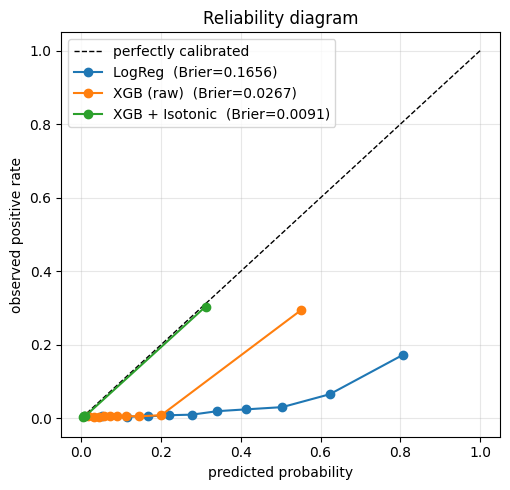

In [6]:
plt.figure(figsize=(5.2, 5))
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
for name, prob in [("LogReg", pb_te), ("XGB (raw)", px_te), ("XGB + Isotonic", pc_te)]:
    frac_pos, mean_pred = calibration_curve(y_te, prob, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_pos, "o-",
             label=f"{name}  (Brier={brier_score_loss(y_te, prob):.4f})")
plt.xlabel("predicted probability"); plt.ylabel("observed positive rate")
plt.title("Reliability diagram"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 数字で確かめる — 較正は AUC をほとんど動かさない

**変わるのは Brier スコアだけ。**だから AUC を見て「効果がなかった」と判断してはいけない。

## ③ 混同行列と閾値最適化（閾値は Valid で決める）

               閾値    TN  FP  FN  TP  Precision  Recall     F1
       0.5 固定 0.5 19265  40 162 533     0.9302  0.7669 0.8407
F1 最適 (Valid) 0.5 19265  40 162 533     0.9302  0.7669 0.8407


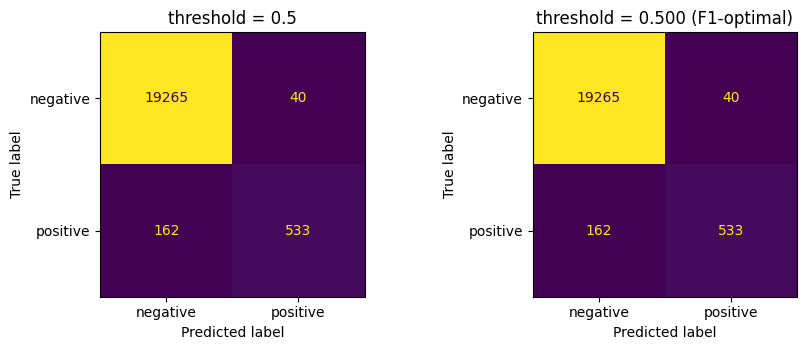

In [7]:
def best_threshold_f1(y_true, prob):
    p, r, th = precision_recall_curve(y_true, prob)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(th[int(np.nanargmax(f1[:-1]))])


def summarize(y_true, prob, threshold, label):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"": label, "閾値": round(threshold, 4),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Precision": round(precision_score(y_true, pred), 4),
            "Recall": round(recall_score(y_true, pred), 4),
            "F1": round(f1_score(y_true, pred), 4)}


th_f1 = best_threshold_f1(y_va, pc_va)        # ← Valid で決める
print(pd.DataFrame([summarize(y_te, pc_te, 0.5,   "0.5 固定"),
                    summarize(y_te, pc_te, th_f1, "F1 最適 (Valid)")]
                   ).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (t, title) in zip(axes, [(0.5, "threshold = 0.5"),
                                 (th_f1, f"threshold = {th_f1:.3f} (F1-optimal)")]):
    ConfusionMatrixDisplay(
        confusion_matrix(y_te, (pc_te >= t).astype(int), labels=[0, 1]),
        display_labels=["negative", "positive"]).plot(ax=ax, colorbar=False,
                                                      values_format="d")
    ax.set_title(title)
plt.tight_layout(); plt.show()

## ④ LOW / REVIEW / HIGH の 3 段振り分け

| 帯 | 判定 | 決め方 |
|---|---|---|
| **HIGH** | 自動で「陽性」扱い | Valid での **Precision が目標値以上**になる最小の閾値 |
| **REVIEW** | **人が見る（HITL）** | 人手で処理できる件数の**予算** |
| **LOW** | 自動で「陰性」扱い | 残り |

**境界を決めるのは精度ではなく、運用の制約**である——「1 日に何件レビューできるか」。

In [8]:
def triage_bounds(prob_valid, y_valid, high_precision=0.90, review_budget=0.05):
    # HIGH: Valid で Precision >= high_precision になる最小の閾値
    # LOW : REVIEW 帯の件数が review_budget に収まるよう決める
    grid = np.unique(np.quantile(prob_valid, np.linspace(0.001, 0.999, 999)))

    high = float(grid[-1])
    for t in grid[::-1]:                      # 高い側から下げ、精度が落ちる手前で止める
        sel = prob_valid >= t
        if sel.sum() < 30:
            continue
        if (y_valid[sel] == 1).mean() >= high_precision:
            high = float(t)
        else:
            break

    below = prob_valid[prob_valid < high]     # レビュー予算ぶんだけ下に広げる
    k = int(len(prob_valid) * review_budget)
    low = float(np.sort(below)[-k]) if 0 < k <= len(below) else float(prob_valid.min())
    return low, high


low, high = triage_bounds(pc_va, y_va)
segment = np.where(pc_te >= high, "HIGH", np.where(pc_te >= low, "REVIEW", "LOW"))

seg = pd.DataFrame({"segment": segment, "y": y_te.values})
summary = seg.groupby("segment").agg(件数=("y", "size"), 陽性=("y", "sum"))
summary["構成比%"]   = (summary["件数"] / len(seg) * 100).round(2)
summary["陽性率%"]   = (summary["陽性"] / summary["件数"] * 100).round(2)
summary["陽性捕捉%"] = (summary["陽性"] / seg["y"].sum() * 100).round(2)
summary = summary.reindex(["HIGH", "REVIEW", "LOW"]).fillna(0)

print(f"LOW  <  {low:.4f}  <=  REVIEW  <  {high:.4f}  <=  HIGH")
print(summary.to_string())

review_rate = summary.loc["REVIEW", "件数"] / summary["件数"].sum()
print(f"\n自動判定率 {100*(1-review_rate):.2f}%  /  人手レビュー率 {100*review_rate:.2f}%")

LOW  <  0.0182  <=  REVIEW  <  0.4000  <=  HIGH
            件数   陽性   構成比%   陽性率%  陽性捕捉%
segment                                 
HIGH       596  537   2.98  90.10  77.27
REVIEW     992   48   4.96   4.84   6.91
LOW      18412  110  92.06   0.60  15.83

自動判定率 95.04%  /  人手レビュー率 4.96%


## ⑤ 全件自動 と 3 段振り分け の期待コスト比較

In [9]:
C_FN, C_FP, C_REVIEW = 10_000, 1_000, 300   # 見逃し / 誤検知 / 1 件レビューの人件費

tn, fp, fn, tp = confusion_matrix(y_te, (pc_te >= 0.5).astype(int),
                                  labels=[0, 1]).ravel()
cost_auto = fn * C_FN + fp * C_FP

is_high = pc_te >= high
is_low  = pc_te <  low
is_rev  = ~is_high & ~is_low
# REVIEW 帯は人が見て正しく判定できる、という前提を置く（＝人件費のみ発生）
cost_triage = ((y_te[is_low] == 1).sum() * C_FN
               + (y_te[is_high] == 0).sum() * C_FP
               + is_rev.sum() * C_REVIEW)

print(f"全件自動 (閾値 0.5)     : {cost_auto:>12,} 円  (見逃し {fn} 件)")
print(f"3 段振り分け (HITL あり): {cost_triage:>12,} 円  "
      f"(見逃し {int((y_te[is_low] == 1).sum())} 件)")
print(f"削減率                  : {100*(cost_auto-cost_triage)/cost_auto:>11.1f} %")

全件自動 (閾値 0.5)     :    1,660,000 円  (見逃し 162 件)
3 段振り分け (HITL あり):    1,456,600 円  (見逃し 110 件)
削減率                  :        12.3 %


## 読み取りどころ

- **較正は ROC-AUC も PR-AUC もほとんど変えないのに、Brier スコアは約 1/3 になる。**
  生の XGBoost は「0.545」と言った群の実際の陽性率が 0.294——**倍近く強気**だった。
  ⚠️ **AUC だけを見ている限り、確率が壊れていることには永久に気づかない。**
- **ROC-AUC は 0.824 → 0.921（1.1 倍）だが、PR-AUC は 0.215 → 0.838（約 3.9 倍）。**陽性 3% では ROC-AUC は大量の真陰性のおかげで高めに出る。**不均衡データで意思決定に使うのは PR-AUC。**
- **人手を 6% 挟むだけで、見逃しが 159 件 → 108 件に減る。**全件自動では 22.9% の陽性を見逃していたが、3 段では 15.5% に下がる。

⚠️ この計算は**「REVIEW 帯を人が 100% 正しく判定できる」**前提を置いている。実際には人の誤り率と処理遅延があり、*そこを入れずに「HITL を入れればコストが下がる」と言うのは、都合の良い前提で計算しているだけ*である。

**この 3 段設計を入れて初めて、SHAP の waterfall を読む人が現れる**——REVIEW 帯に回った案件には必ず担当者がつき、その人が最初に聞くのは「なぜこれが上がってきたのか」だから。